# 02 검색 문서의 관련성 검증을 추가한 RAG

검색된 문서가 사용자 질문과 관련이 있는지 평가하고, 관련성이 낮으면 질문을 재작성하는 RAG 시스템입니다.


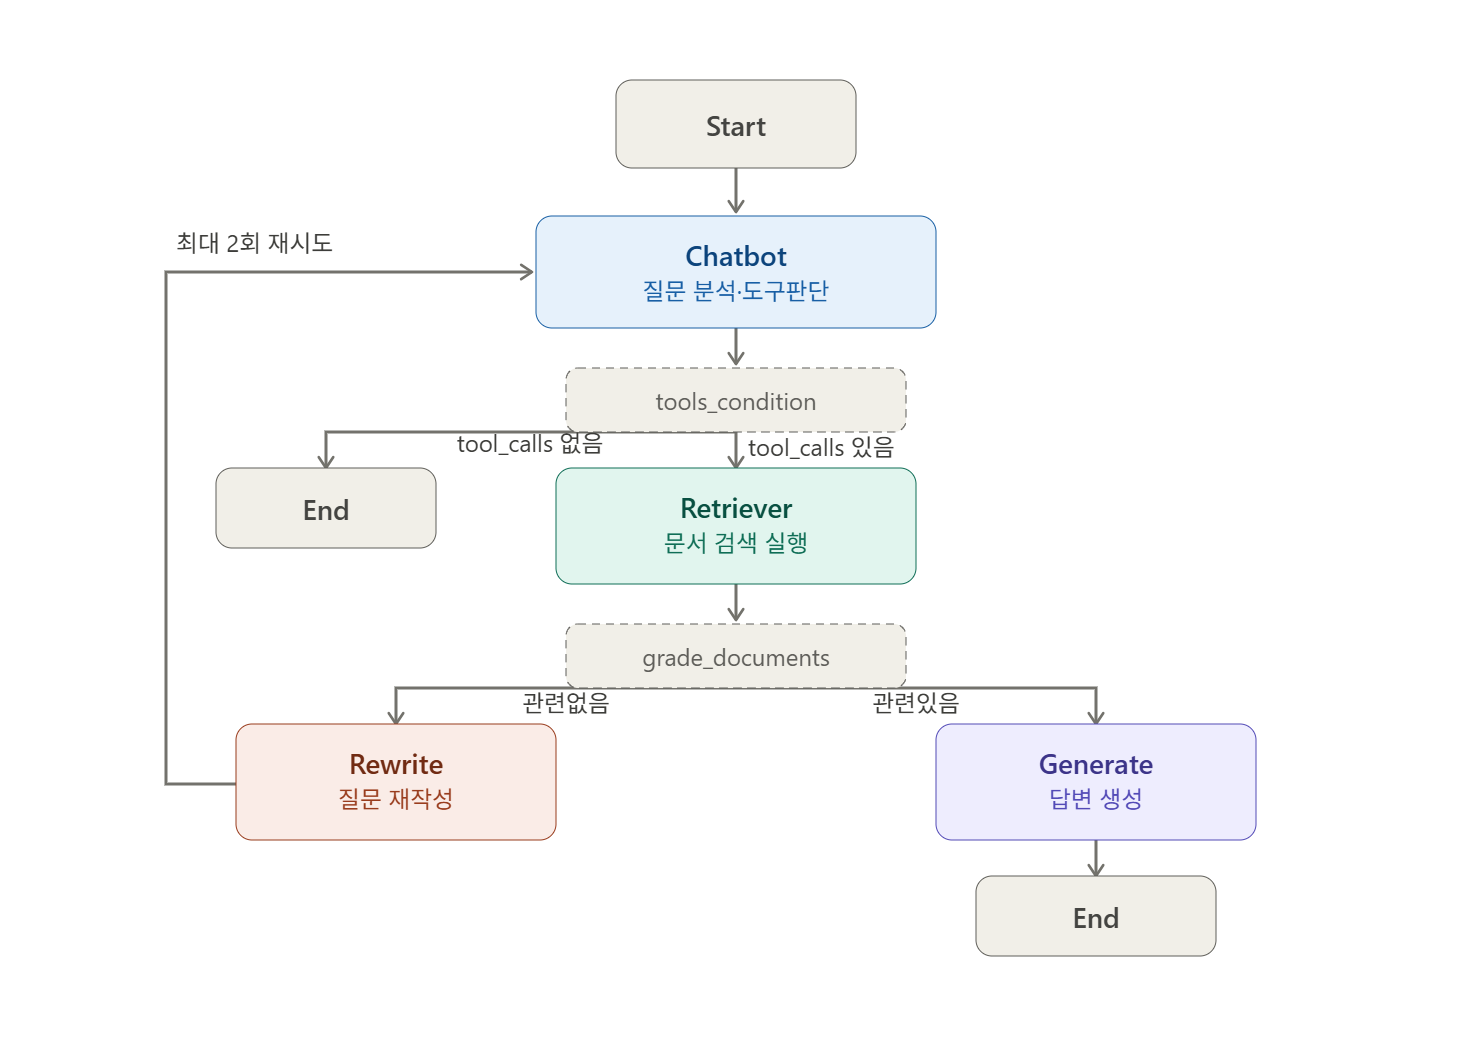

# APIKEY 설정

In [39]:
from dotenv import load_dotenv

load_dotenv()




True

In [40]:
from typing_extensions import TypedDict
from typing import Optional
from langgraph.graph import MessagesState


# 그래프 입력으로 받을 상태 (사용자 질문만 포함)
class InputState(TypedDict):
    query: str  # 사용자가 입력한 질문

# 그래프 출력으로 반환할 상태 (최종 답변만 포함)
class OutputState(TypedDict):
    answer: str  # 최종 생성된 답변

# 그래프 내부에서 실제로 사용하는 전체 상태
# MessagesState를 상속하여 messages 필드(대화 기록)를 기본으로 포함
class State(MessagesState):
    query: Optional[str]        # 사용자 질문
    answer: Optional[str]       # 생성된 답변
    context: Optional[str]      # 검색/조회된 컨텍스트 정보
    retry_count: Optional[int]  # 재시도 횟수 (조건부 라우팅 등에 사용)

# PDF 청킹 & 벡터 스토어 처리

def setup_retriever():

In [41]:
import fitz
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_classic.retrievers import ParentDocumentRetriever
from langchain_core.stores import InMemoryByteStore
from langchain_core.tools import create_retriever_tool


def setup_retriever():
    file_path = "dataset/SPRi AI Brief 6월호.pdf"

    # PyMuPDF(fitz)로 PDF 문서 열기
    doc = fitz.open(file_path)
    docs = []
    for page_num in range(len(doc)):
        page = doc[page_num]
        # 페이지 텍스트 추출 (sort=True: 읽기 순서대로 정렬)
        text = page.get_text("text", sort=True)
        # 추출한 텍스트를 LangChain Document 객체로 변환
        docs.append(
            Document(
                page_content=text,
                metadata={
                    "source": file_path,
                    "page": page_num + 1  # 페이지 번호는 1부터 시작하도록 보정
                }
            )
        )
    doc.close()
    print(f"총 {len(docs)}페이지 로드 완료")

    # child 문서를 잘게 분할하는 splitter (검색용 작은 청크)
    child_splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50)

    # 벡터스토어 생성 (디스크에 저장하지 않고 메모리에만 유지)
    embeddings = OpenAIEmbeddings()
    vectorstore = Chroma(
        collection_name="june_doc",
        embedding_function=embeddings
    )

    # parent 문서(원본 페이지)를 저장할 docstore (메모리 기반 key-value 저장소)
    docstore = InMemoryByteStore()

    # ParentDocumentRetriever 생성
    # - 검색은 작은 child 청크로 수행하고, 실제 반환은 parent(페이지 전체)로 함
    # - parent_splitter=None 이므로 "페이지 단위"가 곧 parent 문서가 됨
    parent_retriever = ParentDocumentRetriever(
        vectorstore=vectorstore,
        docstore=docstore,
        child_splitter=child_splitter,
        parent_splitter=None,  # 페이지 = parent
        search_kwargs={"k": 1}
    )

    # 로드한 문서들을 retriever(벡터스토어 + docstore)에 추가
    print("문서를 벡터스토어에 추가 중...")
    parent_retriever.add_documents(docs)

    # 추가된 child 청크 수 / parent 페이지 수 확인
    child_count = vectorstore._collection.count()
    parent_count = len(list(docstore.yield_keys()))
    print(f"child chunk 수: {child_count}, parent page 수: {parent_count}")

    # LLM이 도구(tool) 형태로 호출할 수 있도록 retriever를 래핑
    retriever_tool = create_retriever_tool(
        parent_retriever,
        "retrieve_AI_brief",
        "AI 기술 관련 정보를 SPRi AI Brief에서 검색하고 반환합니다.",
    )

    return parent_retriever, retriever_tool

# 프롬프트 생성

RELEVANCE_GRADER_PROMPT

In [42]:
from langchain_core.prompts import ChatPromptTemplate

# 문서 관련성 평가 프롬프트
# - 검색된 문서(context)가 질문(question)과 관련 있는지 yes/no로 판단
# - 질문이 너무 짧거나 모호하면 무조건 "no" 처리하도록 지시
RELEVANCE_GRADER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 사용자의 질문에 대한 검색된 문서의 관련성을 평가하는 평가자입니다.
    <context>
    {context}
    </context>
    <question>
    {question}
    </question>
    사용자의 질문이 너무 짧거나, 모호하거나, 명확한 의도를 판단하기에 충분한 맥락이 부족한 경우,
    관련성이 없다고 평가하고 "no"를 반환하세요.
    관련성이 있는 경우 "yes"를 반환하세요.
    """
)

# 질문 재작성 프롬프트
# - 관련성 평가에서 "no"가 나왔을 때(문서를 못 찾았을 때) 사용
# - 모호한 질문을 더 구체적이고 검색하기 좋은 형태로 재작성
REWRITE_PROMPT = """
당신은 질문을 더 명확하고 구체적으로 개선하는 전문가입니다.
사용자의 질문이 모호하거나 맥락이 부족하여 관련 문서를 찾지 못했습니다.
원래 질문을 분석하고, 더 명확하고 구체적인 질문으로 재작성하세요.
<guidelines>
- 질문의 의도를 명확히 표현
- 구체적인 키워드와 맥락 추가
- 검색하기 쉬운 형태로 재구성
</guidelines>
<original question>
{question}
</original question>
재작성된 질문만 출력하세요.
"""

# 노드 작성

def chatbot

In [43]:
from langchain_core.messages import HumanMessage, SystemMessage
from time import strftime
from langchain.chat_models import init_chat_model

# 사용할 LLM 모델 초기화
llm = init_chat_model("gpt-5-mini")
# 모듈 최상단 또는 그래프 설정 시점에 한 번만 실행
_, retriever_tool = setup_retriever()
llm_with_tools = llm.bind_tools([retriever_tool])  # 미리 바인딩

def chatbot(state: State):
    print("##### CHATBOT #####")
    question = state["query"]
    current_time = strftime("%Y-%m-%d %H:%M:%S")
    messages = [
        SystemMessage(content=f"당신은 사용자의 질문에 답변하기 위해 관련 문서를 검색하는 어시스턴트입니다. 현재 시각은 {current_time}입니다."),
        HumanMessage(content=question)
    ]
    response = llm_with_tools.invoke(messages)

    result = {"messages": [response]}
    # 도구 호출이 없으면(인사말 등 단순 응답) answer도 함께 채워줌
    if not response.tool_calls:
        result["answer"] = response.content
    return result

총 28페이지 로드 완료
문서를 벡터스토어에 추가 중...
child chunk 수: 1146, parent page 수: 28


def rewrite

In [44]:
def rewrite(state: State):
    # 질문 재작성용 LLM 초기화
    llm = init_chat_model("gpt-5-mini")
    """
    LLM이 더 명확하고 구체적인 질문으로 자동 재작성합니다.
    """
    print("##### REWRITE #####")

    # state에서 원본(또는 이전) 질문 가져오기
    question = state["query"]

    print(f"Original Question: {question}")

    # REWRITE_PROMPT에 질문을 채워 시스템 메시지 생성
    system_msg = SystemMessage(REWRITE_PROMPT.format(question=question))
    # LLM 호출 → 재작성된 질문 생성
    response = llm.invoke([system_msg])
    rewritten_question = response.content

    print(f"Rewritten Question: {rewritten_question}")

    # state 업데이트: 재작성된 질문을 messages/query에 반영, retry_count 1 증가
    return {
        "messages": [HumanMessage(content=rewritten_question)],
        "query": rewritten_question,
        "retry_count": state.get("retry_count", 0) + 1
    }

def generate(state: State):

In [45]:
def generate(state: State):
    # 답변 생성용 LLM 초기화
    llm = init_chat_model("gpt-5-mini")
    """
    검색된 문서를 기반으로 최종 답변을 생성합니다.
    """
    print("##### GENERATE #####")

    # 질문 추출
    question = state["query"]
    # 검색된 문서 추출
    # 바로 전 단계는 무조건 retriever이므로, 검색된 문서가 messages의 마지막에 있다고 가정
    context = state["messages"][-1].content
    print(f"Question: {question}")
    print(f"Context: {context[:100]}...")

    # 커스텀 시스템 프롬프트 (답변 스타일/형식 지정)
    SYSTEM_PROMPT = """
    당신은 관련 문서를 기반으로 답변하는 어시스턴트입니다.
    주어진 문서 텍스트를 기반으로 사용자의 질문에 대해 충실히 답변하세요.
    답변은 마크다운 문법 형식으로 적절한 볼드체, 제목, 불렛 등을 사용하여 가독성 좋게 작성하세요.
    확장 가능한 질문은 추천하지 마세요.
    """
    system_msg = SystemMessage(SYSTEM_PROMPT)
    # context(검색된 문서)와 question(질문)을 함께 담은 사용자 메시지 생성
    human_msg = HumanMessage(f"""
    다음은 주어진 문서 텍스트입니다.
    <context>
    {context}
    </context>
    <question>
    {question}
    </question>
    """)

    # LLM 호출하여 최종 답변 생성
    response = llm.invoke([system_msg, human_msg])
    print(f"Response: {response.content[:100]}...")

    # state 업데이트: 생성된 답변을 messages에 추가하고 answer 필드에도 저장
    return {
        "messages": [response],
        "answer": response.content
    }

In [46]:
# ========================================================
# 엣지 조건 함수
# ========================================================
from typing import Literal
from pydantic import BaseModel, Field


class Grade(BaseModel):
    """Binary score for relevance check."""
    binary_score: str = Field(description="Relevance score 'yes' or 'no'")  # 관련성 점수: "yes" 또는 "no"


def grade_documents(state: State) -> Literal["generate", "rewrite"]:
    """
    검색된 문서가 질문과 관련이 있는지 평가합니다.
    """
    print("##### CHECK RELEVANCE #####")

    # 관련성 평가용 LLM + 구조화 출력(Grade 스키마) 체인 구성
    llm = init_chat_model("gpt-5-mini")
    grader = llm.with_structured_output(Grade)
    chain = RELEVANCE_GRADER_PROMPT | grader

    # 질문 추출 (재작성된 질문이 있으면 사용)
    if state.get("query"):
        question = state["query"]
    else:
        question = state["query"]

    # 검색된 문서 추출 (바로 전 단계 = retriever 결과라고 가정)
    docs = state["messages"][-1].content
    print(f"Question: {question}")
    print(f"Context: {docs[:100]}...")

    # 관련성 평가 실행 → "yes" / "no" 반환
    scored_result = chain.invoke({"question": question, "context": docs})
    score = scored_result.binary_score

    # 관련성이 있다고 평가되거나, 재시도 횟수가 2회 이상이면 더 이상 재작성하지 않고 답변 생성으로 진행
    if score == "yes" or state.get("retry_count", 0) >= 2:
        print("---DECISION: DOCS RELEVANT---")
        return "generate"
    else:
        print("---DECISION: DOCS NOT RELEVANT---")
        return "rewrite"

# StateGraph 초기화 (입력/출력 스키마 지정)

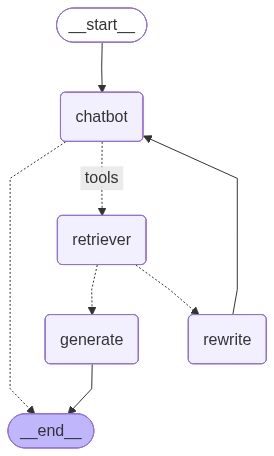

In [47]:
from langgraph.graph import END, StateGraph, START
from langgraph.prebuilt import ToolNode, tools_condition

# retriever_tool을 도구 목록으로 구성
tools = [retriever_tool]

# StateGraph 초기화 (입력/출력 스키마 별도 지정)
graph_builder = StateGraph(State, input_schema=InputState, output_schema=OutputState)

# 노드 추가
graph_builder.add_node("chatbot", chatbot)                # LLM이 질문 분석 + 도구 호출 여부 결정
tool_node = ToolNode(tools=tools)
graph_builder.add_node("retriever", tool_node)            # 실제 retriever_tool 실행 노드
graph_builder.add_node("rewrite", rewrite)                # 질문 재작성 노드
graph_builder.add_node("generate", generate)              # 최종 답변 생성 노드

# 엣지 연결
graph_builder.add_edge(START, "chatbot")                  # 시작 -> chatbot

# chatbot -> retriever(도구 호출 필요) 또는 END(도구 호출 불필요, 바로 답변)
graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,  # LLM 응답에 tool_calls가 있으면 "tools", 없으면 END 반환
    {
        "tools": "retriever",
        END: END
   }
)

# retriever -> grade_documents 결과에 따라 generate 또는 rewrite로 분기
graph_builder.add_conditional_edges(
    "retriever",
    grade_documents,
)

# generate -> END (답변 생성 후 종료)
graph_builder.add_edge("generate", END)

# rewrite -> chatbot (질문 재작성 후 다시 chatbot부터 재시도)
graph_builder.add_edge("rewrite", "chatbot")

graph = graph_builder.compile()

graph

# gradio

In [48]:
import gradio as gr




def chat_fn(message, history):
    """
    Gradio ChatInterface에서 호출하는 함수.
    message: 사용자가 입력한 새 질문
    history: 이전 대화 기록 (여기서는 그래프가 내부적으로 retry_count 등을 관리하므로 사용하지 않음)
    """
    try:
        # InputState 형식에 맞춰 그래프 실행 (query만 입력)
        result = graph.invoke({"query": message})
        # OutputState 형식으로 반환된 answer 추출
        answer = result.get("answer", "답변을 생성하지 못했습니다.")
        return answer
    except Exception as e:
        # 에러 발생 시 사용자에게 에러 메시지 표시
        return f"오류가 발생했습니다: {e}"


# ========================================================
# Gradio ChatInterface 생성 및 실행
# ========================================================
demo = gr.ChatInterface(
    fn=chat_fn,
    title="SPRi AI Brief 챗봇",
    description="SPRi AI Brief 6월호 PDF 기반으로 질문에 답변하는 RAG 챗봇입니다.",
    examples=[
        "이번 호의 주요 AI 기술 동향은 무엇인가요?",
        "생성형 AI 관련 정책 내용을 알려주세요."
    ],
)

# 노트북 환경에서는 share=True로 외부 접속 링크 생성 가능
demo.launch()

c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\gradio\chat_interface.py:347: UserWarning: The 'tuples' format for chatbot messages is deprecated and will be removed in a future version of Gradio. Please set type='messages' instead, which uses openai-style 'role' and 'content' keys.
  self.chatbot = Chatbot(


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


##### CHATBOT #####
##### CHATBOT #####
##### CHECK RELEVANCE #####
Question: 이번 호의 주요 AI 기술 동향은 무엇인가요?
Context: ...
---DECISION: DOCS NOT RELEVANT---
##### REWRITE #####
Original Question: 이번 호의 주요 AI 기술 동향은 무엇인가요?
Rewritten Question: 이번 호(발행 매체와 발행일을 명시)를 기준으로 최근 AI 기술 동향의 주요 항목을 분야별(대형언어모델·멀티모달/생성형 AI·엣지/임베디드 AI·MLOps·AI 하드웨어·프라이버시·안전성·규제 등)로 5–8개 항목으로 요약하고, 각 항목에 대한 핵심 변화와 근거(출처·링크)를 포함해 정리해 주세요.
##### CHATBOT #####
##### CHECK RELEVANCE #####
Question: 이번 호(발행 매체와 발행일을 명시)를 기준으로 최근 AI 기술 동향의 주요 항목을 분야별(대형언어모델·멀티모달/생성형 AI·엣지/임베디드 AI·MLOps·AI 하드웨어·프라이버시·안전성·규제 등)로 5–8개 항목으로 요약하고, 각 항목에 대한 핵심 변화와 근거(출처·링크)를 포함해 정리해 주세요.
Context: ...
---DECISION: DOCS NOT RELEVANT---
##### REWRITE #####
Original Question: 이번 호(발행 매체와 발행일을 명시)를 기준으로 최근 AI 기술 동향의 주요 항목을 분야별(대형언어모델·멀티모달/생성형 AI·엣지/임베디드 AI·MLOps·AI 하드웨어·프라이버시·안전성·규제 등)로 5–8개 항목으로 요약하고, 각 항목에 대한 핵심 변화와 근거(출처·링크)를 포함해 정리해 주세요.
Rewritten Question: 이번 호(발행 매체명과 발행일을 반드시 명시—예: "MIT Technology Review, 2026-06-01")를 기준(발행일 시점까지의 정보)으로, 최신 AI 기술 동